# Chan et al. 2021 — Lung (SCLC) · 01 Preprocessing

Small-cell lung cancer (Chan et al. 2021), 10x, malignant cells only. Load → per-sample
min-cell threshold (gap-finding) → overdispersed genes → PCA (no `sc.pp.scale`) → Harmony on
`sample` with a **theta sweep** → neighbours/UMAP over an **n_pcs sweep** → island removal →
compartment split (cell-cycle) → **Gate 1** on the regenerated embedding (per-neighbourhood iLISI +
continuity). Runs in place; house `(3.5,1.5)` deliverable style.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'          # scFates PPT -> rpy2 -> r-mgcv
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Paths — `<Category>/<Dataset>` partition, notebooks run in place

In [3]:
name = os.path.basename(os.getcwd())                    # Chan2021_Lung-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Lung
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# raw input folder is Data_Chan2021_Lung (strip the '-2' re-run suffix)
base = name.split('-')[0] if name.split('-')[-1].isdigit() else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', base)

### Load malignant cells

In [5]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
print('reported SCLC subtypes:', adata.obs['cell_subtype'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Chan2021_Lung
Done.
full atlas: (86662, 26036)
malignant: (51052, 26036) | samples: 34
expression: X max 8.51 (log1p of normalize_total UMI counts)
reported SCLC subtypes: {'SCLC-A': 29099, 'SCLC-N': 18176, 'SCLC-P': 2989, 'NSCLC': 788}


### Per-sample threshold — gap-finding (C1: derived, C2: shown)
Sort per-sample malignant counts, take the largest adjacent ratio. A *dominant* cliff (top gap
≥1.5× the runner-up and dropping below 2×floor) is a real spillover edge → threshold at the
geometric mean of the gap; otherwise fall back to a ≥100 floor. Here a dominant 92→15 cliff sets
the bar between well-populated tumours and doublet-level specks.

In [7]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', n.values.tolist())
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(f'{"dominant spillover cliff" if dominant else "no dominant cliff"} -> threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [5243, 4837, 3946, 3807, 3766, 3213, 3078, 2966, 2746, 2654, 2546, 2283, 1910, 1851, 1419, 1265, 958, 763, 689, 517, 183, 165, 102, 92, 15, 11, 9, 7, 4, 3, 1, 1, 1, 1]
argmax gap 92->15 (ratio 6.13); top/second = 2.04; dominant cliff = True
dominant spillover cliff -> threshold = 37
kept 24/34 samples (min per-sample = 92) -> 50999 cells


### Gene filter + overdispersed selection → PCA (no `sc.pp.scale` before PCA — absent from the reference protocol)

In [9]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3228 over-dispersed features (0:00:08) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3228


### Harmony integration — theta sweep (C1: derived, not inherited)
Chan is a strong patient-specific 10x batch effect (each tumour is largely one SCLC subtype, so
patient ≈ subtype). Sweep integration strength on the same-sample neighbour fraction (lower = better
mixing). Mixing improves sharply to theta=5 then flattens; theta=10 is within noise of theta=5, so
choose the strongest integration that still holds structure — the NSCLC precedent (Qian) also ran
theta=10.

In [11]:
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base_mix = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base_mix,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration chosen for the strong patient-specific batch effect)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)

same-sample neighbour fraction | pre-Harmony 0.829 | sweep {2: 0.268, 5: 0.217, 10: 0.215}
selected theta = 10 (mixing plateaus by theta=5; strongest integration chosen for the strong patient-specific batch effect)


### Neighbours + UMAP — n_pcs sweep (robust range 20–40)
Build the embedding at n_pcs = 20 and 40 (never under-power PCs). The manifold is one continuous
mass at both; keep n_pcs=20 (parsimonious, within the Puram-40 / Kürten-20 precedent band).

In [13]:
umaps = {}
for npc in [20, 40]:
    sc.pp.neighbors(adata, n_pcs=npc, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    umaps[npc] = adata.obsm['X_umap'].copy()
    print(f'built UMAP n_pcs={npc}')
n_pcs = 20
adata.obsm['X_umap'] = umaps[n_pcs]
# rebuild the graph at the chosen n_pcs (used downstream for smoothing + neighbors)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
print('chosen n_pcs =', n_pcs)

built UMAP n_pcs=20
built UMAP n_pcs=40
chosen n_pcs = 20


### Island removal — UMAP radius graph, keep the largest connected component

In [15]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 1 cells in 1 detached islands
after island removal: 50998 cells


### Sub-region biology — cell-cycle compartments (biology before geometry)
The manifold is organised largely by proliferation (a cycling vs resting axis). Split at low Leiden
resolution and label the higher-cycling lobe *Cycling*, the other *Body*, confirmed by a
proliferation-marker score. This is a diagnostic split for the Gate-1 biology check — both
compartments carry multiple samples and enter the trajectory together (no scoping; the developmental
axis is shown cell-cycle-free in 02).

In [17]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
cyc_by_lobe = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('cycling fraction per lobe:', cyc_by_lobe.round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
cyc_lobe = cyc_by_lobe.idxmax()
lab_map = {l: ('Cycling' if l==cyc_lobe else 'Body') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 32791, '2': 12116, '1': 6091}
overall cycling fraction: 0.417
cycling fraction per lobe: {'0': 0.178, '1': 0.771, '2': 0.883}
proliferation score per lobe: {'0': 0.025, '1': 0.825, '2': 0.664}
compartments: {'Body': 38882, 'Cycling': 12116}


### House linear orientation
Store a rigid-rotation embedding `X_umap_lin` (distances preserved) with the developmental origin
pole (pSom-high / Crest-low) on the left, so 01–04 panels share one orientation. This is a display
convenience; the trajectory in 02 is fit on the untouched `X_umap`.

In [19]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]                     # pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],[np.sin(-theta_rot), np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}; rigid rotation {np.degrees(theta_rot):+.1f}deg; origin pole on left')

manifold aspect (max/min std): 1.30; rigid rotation -152.3deg; origin pole on left


### Gate 1 — mixing & continuity (per-neighbourhood iLISI, not a scalar)
iLISI (effective number of samples among the k=90 nearest neighbours) rises from ~1 pre-Harmony to a
large fraction of the 24 samples post-Harmony — samples intermix per-neighbourhood, not as a global
average. The manifold is one connected component after island removal. **Gate 1 = GO.**

In [21]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal);')
print('both compartments contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 8.79 of 24 samples
24 samples share one continuous manifold (one connected component after island removal);
both compartments contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save `processed.h5ad`

In [23]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_subtype','cell_cycle_phase','source','disease'}
for col in adata.obs.columns:
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    v = adata.obs[col]
    if v.dtype == object:
        conv = pd.to_numeric(v, errors='coerce')
        keep_num = v.notna().sum() > 0 and conv.notna().sum() >= 0.9*v.notna().sum()
        adata.obs[col] = conv if keep_num else v.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (50998, 24117)


### Deliverable — `samples.pdf` (Gate-1 integration, house style)
Single sample-coloured manifold on the house `(3.5,1.5)` linear orientation; intermixing across the
strip is the batch-integration evidence.

saved samples.pdf | cells: 50998


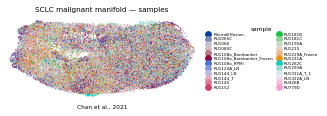

In [25]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, fontsize=4.2, columnspacing=.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('SCLC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])